# Random Forest Classifier – Hotel Booking Cancellation Prediction

**Assignment model 5 of 5**

This notebook trains and evaluates a Random Forest classifier using the same cleaned training and held-out test partitions used by the other four classifiers.

- **Target:** `is_canceled` (`1` = cancelled; `0` = not cancelled)
- **Split:** shared stratified 80:20 split, `random_state=42`
- **Preprocessing:** numerical median imputation; categorical `Unknown` imputation and one-hot encoding
- **Leakage control:** learned preprocessing is fitted inside a scikit-learn pipeline using training data only
- **Scaling:** not applied because tree-based models do not require feature scaling
- **Evaluation:** Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC)

Run `notebooks/01_data_preparation.ipynb` first. Do not create a new split in this notebook. The held-out test set is reserved for final evaluation.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
TARGET = "is_canceled"
MODEL_NAME = "Random Forest"
DECISION_THRESHOLD = 0.50

## 2. Load the common training and test partitions

In [2]:
# Locate the project root whether this notebook is run from the repository root or model/.
root_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next(
    (candidate.resolve() for candidate in root_candidates
     if (candidate / "data" / "train_data.csv").exists()
     and (candidate / "test_data.csv").exists()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/train_data.csv and test_data.csv. "
        "Run notebooks/01_data_preparation.ipynb first."
    )

RESULTS_DIR = REPO_ROOT / "results"
ARTIFACTS_DIR = REPO_ROOT / "model" / "artifacts"
PLOTS_DIR = RESULTS_DIR / "visualizations"
for directory in (RESULTS_DIR, ARTIFACTS_DIR, PLOTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(REPO_ROOT / "data" / "train_data.csv")
test_data = pd.read_csv(REPO_ROOT / "test_data.csv")

if TARGET not in train_data.columns or TARGET not in test_data.columns:
    raise KeyError(f"Both data files must contain target column {TARGET!r}.")
if list(train_data.columns) != list(test_data.columns):
    raise ValueError("Training and test columns do not match or are in a different order.")
if set(train_data[TARGET].dropna().unique()) != {0, 1} or set(test_data[TARGET].dropna().unique()) != {0, 1}:
    raise ValueError("Expected binary target values 0 and 1 in both partitions.")

X_train = train_data.drop(columns=[TARGET]).copy()
y_train = train_data[TARGET].astype(int).copy()
X_test = test_data.drop(columns=[TARGET]).copy()
y_test = test_data[TARGET].astype(int).copy()

print(f"Project root: {REPO_ROOT}")
print(f"Training set: {X_train.shape[0]:,} rows × {X_train.shape[1]} predictors")
print(f"Test set:     {X_test.shape[0]:,} rows × {X_test.shape[1]} predictors")
print("Training and test target proportions:")
display(pd.DataFrame({
    "Training %": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test %": y_test.value_counts(normalize=True).sort_index() * 100,
}).rename(index={0: "Not cancelled (0)", 1: "Cancelled (1)"}).round(2))

Project root: /home/s2026ct05092/Downloads/ML-Assignment-2
Training set: 69,916 rows × 28 predictors
Test set:     17,480 rows × 28 predictors
Training and test target proportions:


,Training %,Test %
is_canceled,,
Not cancelled (0),72.51,72.51
Cancelled (1),27.49,27.49


## 3. Define training-only preprocessing and the Random Forest classifier

Numerical predictors are median-imputed. Categorical predictors (including the `agent` identifier) are imputed with `Unknown` and one-hot encoded. All learned transformations are inside the pipeline, so they are fitted only when `model_pipeline.fit(X_train, y_train)` is called.

Random Forest is an ensemble of decision trees trained on bootstrap samples with random feature subsets. Scaling is not required for tree splits. The configuration below is fixed before evaluating the held-out test set: 250 trees, a maximum depth of 20, minimum leaf size of 5, square-root feature sampling, and `balanced_subsample` class weighting. The class-weight option gives each bootstrap sample weights that account for its class proportions. The default 0.50 probability threshold is retained; no threshold is tuned against the test set.

In [3]:
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

if not numeric_features and not categorical_features:
    raise ValueError("No usable predictors were found.")

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", dtype=np.float32)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ],
    remainder="drop",
)

classifier = RandomForestClassifier(
    n_estimators=250,
    criterion="gini",
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=5,
    max_features="sqrt",
    bootstrap=True,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier),
])

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print("Classifier configuration:")
print(classifier)

Numeric features (17): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical features (11): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type']
Classifier configuration:
RandomForestClassifier(class_weight='balanced_subsample', max_depth=20,
                       min_samples_leaf=5, min_samples_split=20,
                       n_estimators=250, n_jobs=-1, random_state=42)


## 4. Train the model

In [4]:
# The full preprocessing + model pipeline is fitted on training rows only.
start_time = time.time()
model_pipeline.fit(X_train, y_train)
training_seconds = time.time() - start_time

fitted_forest = model_pipeline.named_steps["classifier"]
transformed_feature_count = model_pipeline.named_steps["preprocessor"].transform(X_train.iloc[:1]).shape[1]
print(f"Training completed in {training_seconds:.2f} seconds.")
print(f"Number of trees: {len(fitted_forest.estimators_):,}")
print(f"Maximum configured tree depth: {classifier.max_depth}")
print(f"Number of transformed predictors: {transformed_feature_count:,}")

Training completed in 23.13 seconds.
Number of trees: 250
Maximum configured tree depth: 20
Number of transformed predictors: 570


## 5. Evaluate on the held-out test set

Cancellation (`is_canceled = 1`) is treated as the positive class. AUC is calculated from predicted class-1 probabilities. All six required metrics are reported for the same held-out test partition used by the other classifiers.

In [5]:
y_pred_train = model_pipeline.predict(X_train)
y_pred = model_pipeline.predict(X_test)
y_probability_train = model_pipeline.predict_proba(X_train)[:, 1]
y_probability = model_pipeline.predict_proba(X_test)[:, 1]

# Use the documented 0.50 threshold explicitly so predictions and saved settings agree.
y_pred = (y_probability >= DECISION_THRESHOLD).astype(int)
y_pred_train = (y_probability_train >= DECISION_THRESHOLD).astype(int)

def calculate_metrics(y_true, y_predicted, y_scores):
    return {
        "Accuracy": accuracy_score(y_true, y_predicted),
        "AUC": roc_auc_score(y_true, y_scores),
        "Precision": precision_score(y_true, y_predicted, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_predicted, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, y_predicted, pos_label=1, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_predicted),
    }

train_metrics = calculate_metrics(y_train, y_pred_train, y_probability_train)
test_metrics = calculate_metrics(y_test, y_pred, y_probability)

metric_table = pd.DataFrame({
    "Metric": list(test_metrics.keys()),
    "Training": [train_metrics[name] for name in test_metrics],
    "Test": [test_metrics[name] for name in test_metrics],
})
metric_table[["Training", "Test"]] = metric_table[["Training", "Test"]].astype(float).round(4)
display(metric_table)

# Update exactly one Random Forest row in the shared comparison file.
comparison_path = RESULTS_DIR / "model_comparison.csv"
new_row = pd.DataFrame([{"Model": MODEL_NAME, **test_metrics}])
if comparison_path.exists():
    existing = pd.read_csv(comparison_path)
    if "Model" in existing.columns:
        existing = existing[existing["Model"] != MODEL_NAME]
        comparison = pd.concat([existing, new_row], ignore_index=True)
    else:
        comparison = new_row
else:
    comparison = new_row
comparison.to_csv(comparison_path, index=False, float_format="%.6f")

pd.DataFrame([
    {"Dataset": "Train", **train_metrics},
    {"Dataset": "Test", **test_metrics},
]).to_csv(RESULTS_DIR / "random_forest_metrics.csv", index=False, float_format="%.6f")

pd.DataFrame({
    "actual_is_canceled": y_test.to_numpy(),
    "predicted_is_canceled": y_pred,
    "predicted_probability_cancelled": y_probability,
}).to_csv(RESULTS_DIR / "random_forest_test_predictions.csv", index=False, float_format="%.6f")

print("Updated model comparison:")
display(pd.read_csv(comparison_path).round(4))

,Metric,Training,Test
0,Accuracy,0.7929,0.7793
1,AUC,0.9068,0.8887
2,Precision,0.5823,0.5659
3,Recall,0.8726,0.8468
4,F1,0.6985,0.6784
5,MCC,0.5763,0.5449


Updated model comparison:


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Decision Tree,0.7656,0.8756,0.5463,0.8689,0.6708,0.5358
1,K-Nearest Neighbors,0.8177,0.8709,0.6869,0.6191,0.6513,0.5297
2,Logistic Regression,0.7728,0.8656,0.5587,0.8256,0.6664,0.5257
3,Gaussian Naive Bayes,0.7165,0.7697,0.4890,0.6957,0.5743,0.3844
4,Random Forest,0.7793,0.8887,0.5659,0.8468,0.6784,0.5449


## 6. Confusion matrix, ROC curve and metric visualisation

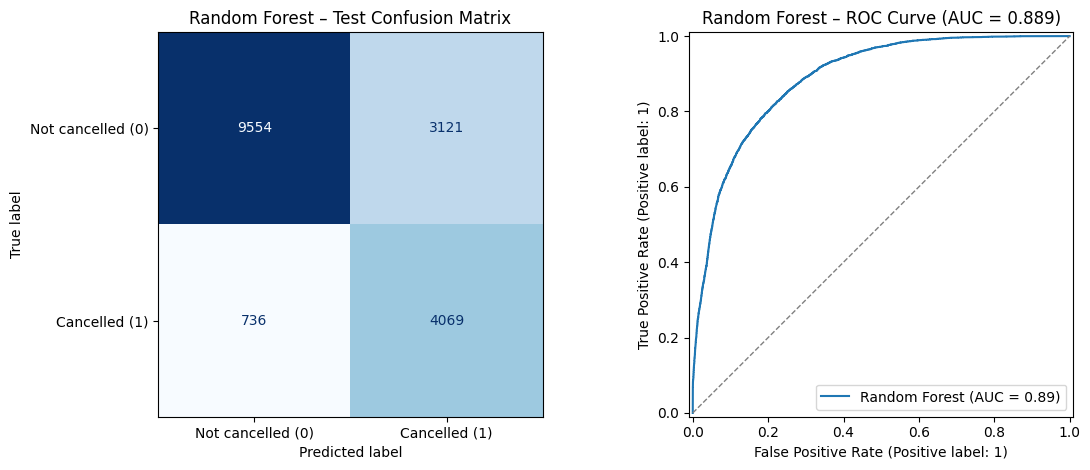

Saved: results/visualizations/random_forest_confusion_matrix_roc.png


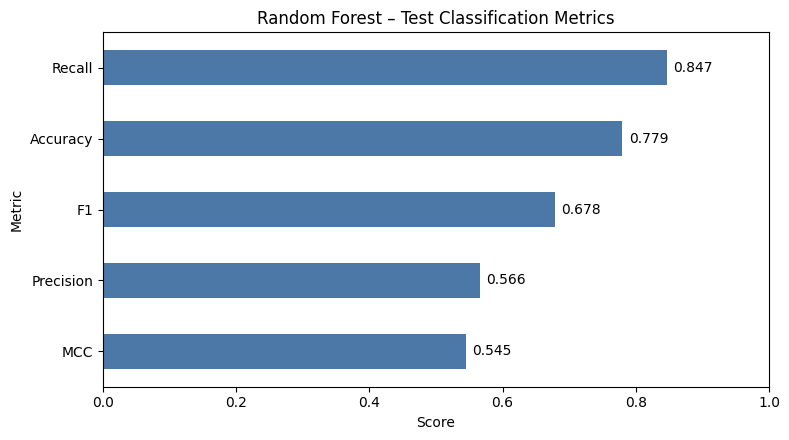

Saved: results/visualizations/random_forest_metrics.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not cancelled (0)", "Cancelled (1)"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Random Forest – Test Confusion Matrix")

RocCurveDisplay.from_predictions(y_test, y_probability, ax=axes[1], name="Random Forest")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
axes[1].set_title(f"Random Forest – ROC Curve (AUC = {test_metrics['AUC']:.3f})")

plt.tight_layout()
confusion_roc_path = PLOTS_DIR / "random_forest_confusion_matrix_roc.png"
plt.savefig(confusion_roc_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {confusion_roc_path.relative_to(REPO_ROOT)}")

metric_plot = pd.Series(test_metrics).drop(labels=["AUC"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
metric_plot.plot(kind="barh", ax=ax, color="#4C78A8", xlim=(0, 1))
ax.set_title("Random Forest – Test Classification Metrics")
ax.set_xlabel("Score")
ax.set_ylabel("Metric")
for y_pos, value in enumerate(metric_plot.values):
    ax.text(value + 0.01, y_pos, f"{value:.3f}", va="center")
plt.tight_layout()
metric_plot_path = PLOTS_DIR / "random_forest_metrics.png"
plt.savefig(metric_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {metric_plot_path.relative_to(REPO_ROOT)}")

## 7. Feature importance

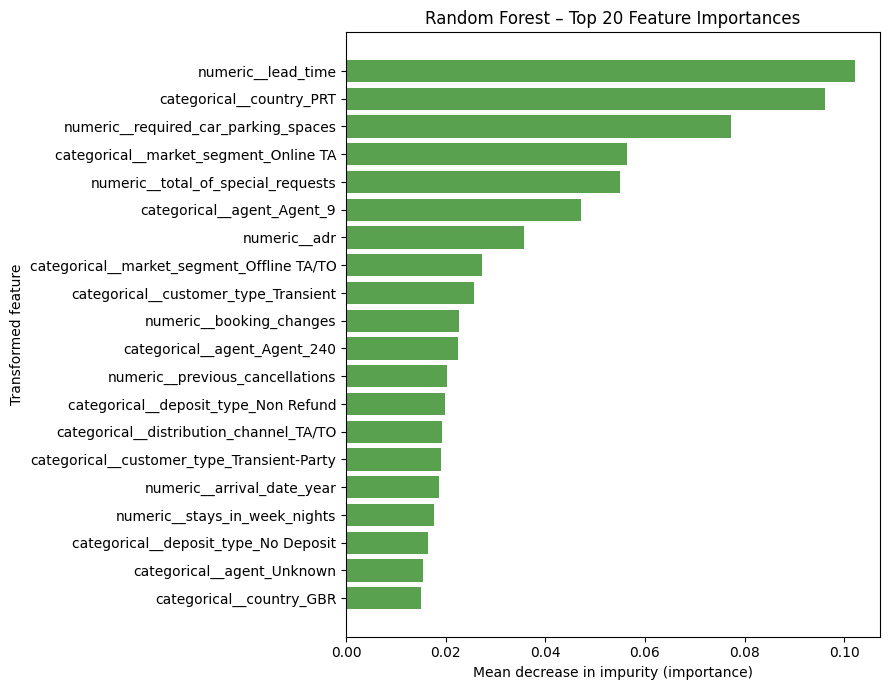

Saved: results/visualizations/random_forest_top_feature_importances.png


,feature,importance
0,numeric__lead_time,0.102085
166,categorical__country_PRT,0.096132
15,numeric__required_car_parking_spaces,0.077358
213,categorical__market_segment_Online TA,0.056488
16,numeric__total_of_special_requests,0.054985
555,categorical__agent_Agent_9,0.047096
14,numeric__adr,0.035719
212,categorical__market_segment_Offline TA/TO,0.027304
568,categorical__customer_type_Transient,0.025684
12,numeric__booking_changes,0.022748


In [7]:
# Impurity-based feature importances are useful for model inspection, but they are not causal effects.
feature_names = model_pipeline.named_steps["preprocessor"].get_feature_names_out()
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": fitted_forest.feature_importances_,
}).sort_values("importance", ascending=False)
feature_importance.to_csv(RESULTS_DIR / "random_forest_feature_importances.csv", index=False)

top_features = feature_importance.head(20).sort_values("importance", ascending=True)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_features["feature"], top_features["importance"], color="#59A14F")
ax.set_title("Random Forest – Top 20 Feature Importances")
ax.set_xlabel("Mean decrease in impurity (importance)")
ax.set_ylabel("Transformed feature")
plt.tight_layout()
importance_plot_path = PLOTS_DIR / "random_forest_top_feature_importances.png"
plt.savefig(importance_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {importance_plot_path.relative_to(REPO_ROOT)}")
display(feature_importance.head(15).round(6))

## 8. Save the fitted pipeline and model configuration

In [8]:
model_path = ARTIFACTS_DIR / "random_forest_pipeline.joblib"
joblib.dump(model_pipeline, model_path, compress=3)

model_configuration = {
    "model": MODEL_NAME,
    "target": TARGET,
    "positive_class": 1,
    "random_state": RANDOM_STATE,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "train_test_split": "80:20 stratified; generated once in 01_data_preparation.ipynb",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "preprocessing": {
        "numeric_imputer": "median",
        "numeric_scaler": "not used; not required for tree-based models",
        "categorical_imputer": "constant: Unknown",
        "categorical_encoder": "OneHotEncoder(handle_unknown=ignore, dtype=float32)",
        "fit_policy": "All learned preprocessing fitted on training data only",
    },
    "classifier": {
        "type": "RandomForestClassifier",
        "n_estimators": 250,
        "criterion": "gini",
        "max_depth": 20,
        "min_samples_split": 20,
        "min_samples_leaf": 5,
        "max_features": "sqrt",
        "bootstrap": True,
        "class_weight": "balanced_subsample",
        "n_jobs": -1,
        "decision_threshold": DECISION_THRESHOLD,
    },
    "training_seconds": float(training_seconds),
    "transformed_feature_count": int(transformed_feature_count),
    "test_metrics": {key: float(value) for key, value in test_metrics.items()},
    "interpretation_note": "Impurity-based feature importance is descriptive, can be biased toward high-cardinality features, and does not establish causation.",
}
config_path = ARTIFACTS_DIR / "random_forest_config.json"
config_path.write_text(json.dumps(model_configuration, indent=2))

# Reload artifact and verify that it reproduces the same held-out test probabilities and labels.
reloaded_pipeline = joblib.load(model_path)
reloaded_probability = reloaded_pipeline.predict_proba(X_test)[:, 1]
reloaded_predictions = (reloaded_probability >= DECISION_THRESHOLD).astype(int)
if not np.allclose(reloaded_probability, y_probability, rtol=1e-10, atol=1e-12):
    raise AssertionError("Reloaded Random Forest pipeline does not reproduce test probabilities.")
if not np.array_equal(reloaded_predictions, y_pred):
    raise AssertionError("Reloaded Random Forest pipeline does not reproduce test predictions.")

print(f"Saved fitted pipeline: {model_path.relative_to(REPO_ROOT)}")
print(f"Saved configuration: {config_path.relative_to(REPO_ROOT)}")
print("Artifact reload check: passed; predictions match the executed model.")

Saved fitted pipeline: model/artifacts/random_forest_pipeline.joblib
Saved configuration: model/artifacts/random_forest_config.json
Artifact reload check: passed; predictions match the executed model.


## 9. Evidence-based observations

In [9]:
print("Random Forest – observations based on this run")
print(f"• Test accuracy: {test_metrics['Accuracy']:.4f}; test AUC: {test_metrics['AUC']:.4f}.")
print(f"• For cancelled bookings (class 1), precision: {test_metrics['Precision']:.4f}, recall: {test_metrics['Recall']:.4f}, and F1: {test_metrics['F1']:.4f}.")
print(f"• Test MCC: {test_metrics['MCC']:.4f}.")
print(f"• Train–test accuracy gap: {train_metrics['Accuracy'] - test_metrics['Accuracy']:+.4f}; train–test AUC gap: {train_metrics['AUC'] - test_metrics['AUC']:+.4f}.")
if abs(train_metrics['Accuracy'] - test_metrics['Accuracy']) < 0.03 and abs(train_metrics['AUC'] - test_metrics['AUC']) < 0.03:
    print("• The train/test gaps are small in this run; there is no strong sign of a large generalisation gap from these two measures.")
elif (train_metrics['Accuracy'] - test_metrics['Accuracy']) > 0.05 or (train_metrics['AUC'] - test_metrics['AUC']) > 0.05:
    print("• Training metrics exceed test metrics noticeably; this may indicate overfitting and should be considered alongside model complexity.")
else:
    print("• The train–test gap should be interpreted alongside the other models; it is not conclusive evidence of overfitting by itself.")
print("• Random Forest combines many trees and can capture nonlinear interactions, but its predictions are less directly interpretable than a single tree.")
print("• The top impurity-based feature importances are model-specific associations, not causal explanations; high-cardinality features may receive disproportionate importance.")
print("• No decision threshold was tuned on the held-out test data; class predictions use 0.50.")
print("• The overall winner should be selected only after comparing all five models across all six required metrics.")

Random Forest – observations based on this run
• Test accuracy: 0.7793; test AUC: 0.8887.
• For cancelled bookings (class 1), precision: 0.5659, recall: 0.8468, and F1: 0.6784.
• Test MCC: 0.5449.
• Train–test accuracy gap: +0.0136; train–test AUC gap: +0.0181.
• The train/test gaps are small in this run; there is no strong sign of a large generalisation gap from these two measures.
• Random Forest combines many trees and can capture nonlinear interactions, but its predictions are less directly interpretable than a single tree.
• The top impurity-based feature importances are model-specific associations, not causal explanations; high-cardinality features may receive disproportionate importance.
• No decision threshold was tuned on the held-out test data; class predictions use 0.50.
• The overall winner should be selected only after comparing all five models across all six required metrics.


## 10. Files produced

- `results/model_comparison.csv` – shared test-set metric table for all five models
- `results/random_forest_metrics.csv` – training and test metrics
- `results/random_forest_test_predictions.csv` – actual labels, predicted labels and cancellation probabilities
- `results/random_forest_feature_importances.csv` – transformed predictor importance values
- `results/visualizations/random_forest_confusion_matrix_roc.png`
- `results/visualizations/random_forest_metrics.png`
- `results/visualizations/random_forest_top_feature_importances.png`
- `model/artifacts/random_forest_pipeline.joblib` – fitted preprocessing + Random Forest pipeline
- `model/artifacts/random_forest_config.json` – model configuration and test metrics

**Academic integrity:** Review and understand the model assumptions, preprocessing, metrics and results. Be prepared to explain the Random Forest hyperparameters, class weighting, and limitations of impurity-based feature importance.